<a href="https://colab.research.google.com/github/Hossain-Mahmud00/cantera-projects/blob/main/Thermo_properties.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install thermo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.8/608.8 kB 14.5 MB/s eta 0:00:00


In [2]:

from thermo import Chemical

water = Chemical('water', T=350, P=101325)
print(water.phase)
print(water.rho)
print(water.Cp)
print(water.mu)

l
973.7419512246711
4194.462916586701
0.00036855593965487204


In [3]:

for T in [300, 350, 370, 380, 400]:
    w = Chemical('water', T=T, P=101325)
    print(T, w.phase, round(w.rho, 2))

print('Boiling point (K):', w.Tb)

300 l 996.57
350 l 973.74
370 l 960.6
380 g 0.58
400 g 0.55
Boiling point (K): 373.124295848


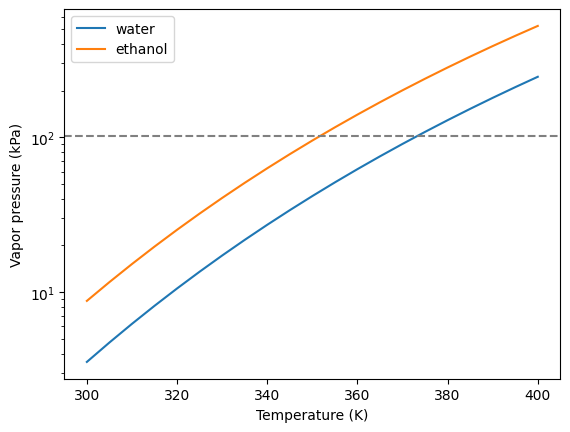

In [4]:

import numpy as np
import matplotlib.pyplot as plt

Ts = np.linspace(300, 400, 21)
for name in ['water', 'ethanol']:
    P = [Chemical(name, T=T).Psat / 1000 for T in Ts]
    plt.semilogy(Ts, P, label=name)

plt.axhline(101.325, color='gray', linestyle='--')
plt.xlabel('Temperature (K)')
plt.ylabel('Vapor pressure (kPa)')
plt.legend()
plt.show()

In [9]:

from thermo import PR

R = 8.314
m = Chemical('methane')
for P_bar in [1, 10, 50, 100, 200]:
    P = P_bar * 1e5
    eos = PR(Tc=m.Tc, Pc=m.Pc, omega=m.omega, T=300, P=P)
    V = getattr(eos, 'V_g', None) or eos.V_l
    Z = P * V / (R * 300)
    rho = m.MW / 1000 / V
    print(P_bar, round(rho, 2), round(Z, 3))

1 0.64 0.998
10 6.57 0.979
50 35.66 0.902
100 77.13 0.834
200 158.53 0.811


373.12429584768347 351.57101467701114


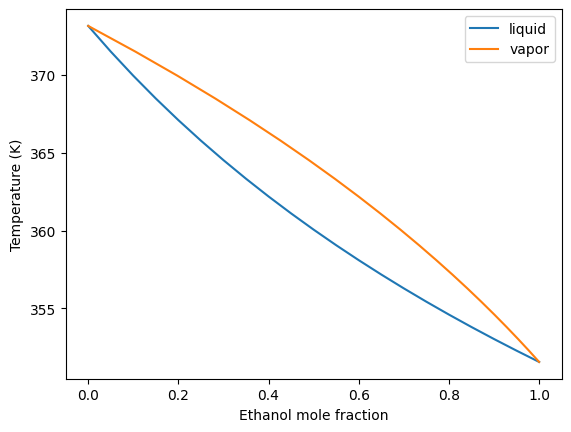

In [10]:

from scipy.optimize import brentq

eth = Chemical('ethanol')
wat = Chemical('water')
P = 101325

def Psat(chem, T):
    return chem.VaporPressure.T_dependent_property(T)

def bubble(x1):
    f = lambda T: x1*Psat(eth, T) + (1-x1)*Psat(wat, T) - P
    T = brentq(f, 330, 400)
    y1 = x1*Psat(eth, T) / P
    return T, y1

xs = np.linspace(0, 1, 21)
res = [bubble(x) for x in xs]
Tb = [r[0] for r in res]
ys = [r[1] for r in res]
print(Tb[0], Tb[-1])

plt.plot(xs, Tb, label='liquid')
plt.plot(ys, Tb, label='vapor')
plt.xlabel('Ethanol mole fraction')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()

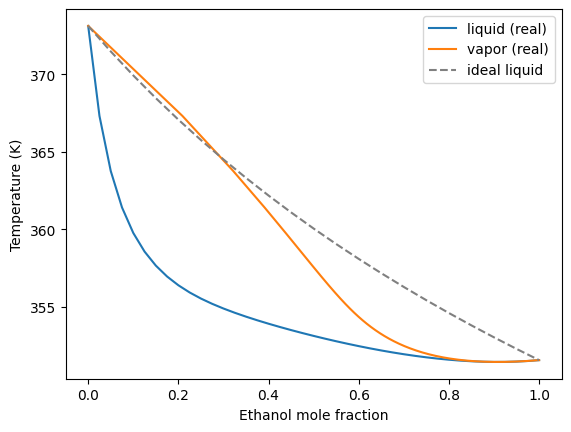

In [11]:

A12, A21 = 1.6798, 0.9227   # Van Laar parameters, ethanol(1)-water(2)

def bubble_real(x1):
    x2 = 1 - x1
    g1 = np.exp(A12*(A21*x2/(A12*x1 + A21*x2))**2)
    g2 = np.exp(A21*(A12*x1/(A12*x1 + A21*x2))**2)
    f = lambda T: x1*g1*Psat(eth, T) + x2*g2*Psat(wat, T) - P
    T = brentq(f, 330, 400)
    y1 = x1*g1*Psat(eth, T) / P
    return T, y1

xs = np.linspace(0, 1, 41)
res2 = [bubble_real(x) for x in xs]
Tb2 = [r[0] for r in res2]
ys2 = [r[1] for r in res2]

plt.plot(xs, Tb2, label='liquid (real)')
plt.plot(ys2, Tb2, label='vapor (real)')
plt.plot(xs, np.interp(xs, xs[::2], Tb[:]), '--', color='gray', label='ideal liquid')
plt.xlabel('Ethanol mole fraction')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()

In [12]:

diff = lambda x: bubble_real(x)[1] - x
xaz = brentq(diff, 0.5, 0.99)
Taz, _ = bubble_real(xaz)
print('Azeotrope: x =', xaz, ' T =', Taz)

Azeotrope: x = 0.9084651326789069  T = 351.4539826629857
